### 1. Importaciones y Configuración Inicial
En este bloque consolidamos todas las librerías necesarias para el funcionamiento del cuaderno.

In [1]:
import os
import gdown

# Configurar rutas del proyecto
TARGET_DIR = '/content/Desarrollo de aplicaciones avanzadas de ciencias computacionales'
FOLDER_URL = 'https://drive.google.com/drive/folders/1ZT31mcZ_fW-3NNC3NHJ-OjU2EmOJ2CXT?usp=sharing'

# Crear la carpeta de destino si no existe
os.makedirs(TARGET_DIR, exist_ok=True)
print(f"Directorio de trabajo configurado en: {TARGET_DIR}")

Directorio de trabajo configurado en: /content/Desarrollo de aplicaciones avanzadas de ciencias computacionales


### 2. Descarga Consolidada de Datos
Este bloque realiza la descarga de la carpeta completa de Google Drive. En caso de que algunos archivos fallen debido a cuotas o permisos restrictivos, el script los rescata de manera individual utilizando métodos alternativos de descarga (`wget` y `curl`).

In [2]:
import os
import gdown
from concurrent.futures import ThreadPoolExecutor

TARGET_DIR = '/content/Desarrollo de aplicaciones avanzadas de ciencias computacionales'
FOLDER_URL = 'https://drive.google.com/drive/folders/1ZT31mcZ_fW-3NNC3NHJ-OjU2EmOJ2CXT?usp=sharing'

os.makedirs(TARGET_DIR, exist_ok=True)

# Diccionario completo de rescate con IDs individuales conocidos
rescue_files = {
    "MC4_PSQ Abril 1 a 15 2025.xlsx": "1xMVD5rfnVwbSP-QyOsJe9kWrFsiKtKPB",
    "MC4_PSQ Abril 16 a 30 2025.xlsx": "148bbJlRC1Uyu3VDrEiHN9l90NpEOJ2Ac",
    "MC4_PSQ Agosto 1 a 15 2025.xlsx": "1_4fVKUHJBtZMtYW_jgJ_CyTC2ZqEwnCU",
    "MC4_PSQ Agosto 16 a 31 2025.xlsx": "10YHfG-UG1-XW34HbAuNOB-hOd0Zt2ICf",
    "MC4_PSQ Diciembre 1 a 15 2025.xlsx": "14gaxV_PPXt9EDIsGJbMT-ylskA654EK7",
    "MC4_PSQ Diciembre 16 a 31 2025.xlsx": "1Mdjs04yilHoJGN3ZS72Xt2oU8z1P047d",
    "MC4_PSQ Enero 1 a 15 2025.xlsx": "1ot8-f1ti0h5rbWlzL8sIO7pnAXbS97KE",
    "MC4_PSQ Enero 16 a 31 2025.xlsx": "1Vr-busbt-q1eWeBAvG_Gfl82Zk9zIzBN",
    "MC4_PSQ Febrero 1 a 15 2025.xlsx": "1MG8eXy2wKhYz-cvEFF5xOuzMzM5ZRUsI",
    "MC4_PSQ Febrero 16 a 28 2025.xlsx": "1KnhKDqb7mGhvAMWKfu-dNs7CswrAzuvS",
    "MC4_PSQ Julio 1 a 15 2025.xlsx": "1Iy1KmeZcS1ngZCx5IFm4qJcEhcm6NhML",
    "MC4_PSQ Julio 16 a 31 2025.xlsx": "1XnFt4cAxG7qq7yqaRj8inEqMmEwXAboX",
    "MC4_PSQ Junio 1 a 15 2025.xlsx": "1cMbbrVYHEVo3do6zOpgjNH4GSYP9LTu8",
    "MC4_PSQ Junio 16 a 30 2025.xlsx": "1dK2KmOOFtsczlP8BeXwfAqyZrm606FxZ",
    "MC4_PSQ Marzo 1 a 15 2025.xlsx": "1mswAchvO5tJAwxpPG43etEpBnctLPb3b",
    "MC4_PSQ Marzo 16 a 31 2025.xlsx": "1JezpbzONdZvwtJesns7mSQzqRSKiLbhM",
    "MC4_PSQ Mayo 1 a 15 2025.xlsx": "1ezWcYljTTBVeCt1oV7qObAtCX_yQhw34",
    "MC4_PSQ Mayo 16 a 31 2025.xlsx": "1qVGGw3llo3_wbI7f8miJAxskgPGPtwzf",
    "MC4_PSQ Noviembre 1 a 15 2025.xlsx": "1htmDtrDhfQW3Mo9a69fijmG9KwD87Hxq",
    "MC4_PSQ Noviembre 16 a 30 2025.xlsx": "1C233hNEA-Wb1MhcelI1KgCAf_o4lzYOL",
    "MC4_PSQ Octubre 1 a 15 2025.xlsx": "1rnFKHgKGsWTwRDdWURXobGpxT1QELhfD",
    "MC4_PSQ Octubre 16 a 31 2025.xlsx": "1dV7t8JT0hjbqSIdiQZk7dgnHeSheePcq",
    "MC4_PSQ Septiembre 1 a 15 2025.xlsx": "1IgVWSRKKUC7XQPVbN2u_beTJiLVlYDxI",
    "MC4_PSQ Septiembre 16 a 30 2025.xlsx": "1ZE4h760SDeNSK3UK6gREqWImWCWnzXwb"
}

def descargar_archivo_individual(item):
    filename, file_id = item
    output_path = os.path.join(TARGET_DIR, filename)

    # Estrategia 1: Omitir si ya está descargado de forma correcta
    if os.path.exists(output_path) and os.path.getsize(output_path) > 1000:
        return f"[Existente] {filename}"

    # Estrategia 2: Intentar descarga rápida con wget directo
    cmd_wget = f'wget --quiet --no-check-certificate "https://docs.google.com/uc?export=download&id={file_id}" -O "{output_path}"'
    os.system(cmd_wget)

    # Si wget falló o el archivo es un HTML de confirmación (pequeño), usar curl simulando navegador
    if not os.path.exists(output_path) or os.path.getsize(output_path) < 1000:
        cmd_curl = f'curl -s -L "https://drive.google.com/uc?export=download&id={file_id}" -A "Mozilla/5.0" -o "{output_path}"'
        os.system(cmd_curl)

    if os.path.exists(output_path) and os.path.getsize(output_path) > 1000:
        return f"[Descargado] {filename}"
    else:
        return f"[Fallo] {filename}"

# Filtrar únicamente los archivos que realmente faltan para no perder tiempo
archivos_faltantes = {k: v for k, v in rescue_files.items() if not (os.path.exists(os.path.join(TARGET_DIR, k)) and os.path.getsize(os.path.join(TARGET_DIR, k)) > 1000)}

if archivos_faltantes:
    print(f"Detectados {len(archivos_faltantes)} archivos faltantes o incompletos. Iniciando descarga paralela...")
    # Usar multi-threading para descargar los archivos faltantes en paralelo
    with ThreadPoolExecutor(max_workers=5) as executor:
        resultados = list(executor.map(descargar_archivo_individual, archivos_faltantes.items()))
    for res in resultados:
        print(res)
else:
    print("Todos los archivos ya están descargados y verificados. ¡Proceso completado al instante!")

Detectados 24 archivos faltantes o incompletos. Iniciando descarga paralela...
[Descargado] MC4_PSQ Abril 1 a 15 2025.xlsx
[Descargado] MC4_PSQ Abril 16 a 30 2025.xlsx
[Descargado] MC4_PSQ Agosto 1 a 15 2025.xlsx
[Descargado] MC4_PSQ Agosto 16 a 31 2025.xlsx
[Descargado] MC4_PSQ Diciembre 1 a 15 2025.xlsx
[Descargado] MC4_PSQ Diciembre 16 a 31 2025.xlsx
[Descargado] MC4_PSQ Enero 1 a 15 2025.xlsx
[Descargado] MC4_PSQ Enero 16 a 31 2025.xlsx
[Descargado] MC4_PSQ Febrero 1 a 15 2025.xlsx
[Descargado] MC4_PSQ Febrero 16 a 28 2025.xlsx
[Descargado] MC4_PSQ Julio 1 a 15 2025.xlsx
[Descargado] MC4_PSQ Julio 16 a 31 2025.xlsx
[Descargado] MC4_PSQ Junio 1 a 15 2025.xlsx
[Descargado] MC4_PSQ Junio 16 a 30 2025.xlsx
[Descargado] MC4_PSQ Marzo 1 a 15 2025.xlsx
[Descargado] MC4_PSQ Marzo 16 a 31 2025.xlsx
[Descargado] MC4_PSQ Mayo 1 a 15 2025.xlsx
[Descargado] MC4_PSQ Mayo 16 a 31 2025.xlsx
[Descargado] MC4_PSQ Noviembre 1 a 15 2025.xlsx
[Descargado] MC4_PSQ Noviembre 16 a 30 2025.xlsx
[Descargado

### 3. Verificación y Listado de Archivos
Este bloque lista de manera ordenada todos los archivos descargados exitosamente en la carpeta destino para confirmar el éxito del proceso.

In [3]:
import os

TARGET_DIR = '/content/Desarrollo de aplicaciones avanzadas de ciencias computacionales'

if os.path.exists(TARGET_DIR):
    archivos = sorted([f for f in os.listdir(TARGET_DIR) if not f.startswith('.')])
    print(f"Archivos detectados con éxito en la carpeta ({len(archivos)} archivos):\n")
    for archivo in archivos:
        print(f"[✓] {archivo}")
else:
    print(f"Error: El directorio {TARGET_DIR} no fue encontrado.")

Archivos detectados con éxito en la carpeta (24 archivos):

[✓] MC4_PSQ Abril 1 a 15 2025.xlsx
[✓] MC4_PSQ Abril 16 a 30 2025.xlsx
[✓] MC4_PSQ Agosto 1 a 15 2025.xlsx
[✓] MC4_PSQ Agosto 16 a 31 2025.xlsx
[✓] MC4_PSQ Diciembre 1 a 15 2025.xlsx
[✓] MC4_PSQ Diciembre 16 a 31 2025.xlsx
[✓] MC4_PSQ Enero 1 a 15 2025.xlsx
[✓] MC4_PSQ Enero 16 a 31 2025.xlsx
[✓] MC4_PSQ Febrero 1 a 15 2025.xlsx
[✓] MC4_PSQ Febrero 16 a 28 2025.xlsx
[✓] MC4_PSQ Julio 1 a 15 2025.xlsx
[✓] MC4_PSQ Julio 16 a 31 2025.xlsx
[✓] MC4_PSQ Junio 1 a 15 2025.xlsx
[✓] MC4_PSQ Junio 16 a 30 2025.xlsx
[✓] MC4_PSQ Marzo 1 a 15 2025.xlsx
[✓] MC4_PSQ Marzo 16 a 31 2025.xlsx
[✓] MC4_PSQ Mayo 1 a 15 2025.xlsx
[✓] MC4_PSQ Mayo 16 a 31 2025.xlsx
[✓] MC4_PSQ Noviembre 1 a 15 2025.xlsx
[✓] MC4_PSQ Noviembre 16 a 30 2025.xlsx
[✓] MC4_PSQ Octubre 1 a 15 2025.xlsx
[✓] MC4_PSQ Octubre 16 a 31 2025.xlsx
[✓] MC4_PSQ Septiembre 1 a 15 2025.xlsx
[✓] MC4_PSQ Septiembre 16 a 30 2025.xlsx


### 4. Consolidación de Datos y Análisis Exploratorio (EDA)
En esta sección uniremos todos los archivos individuales de Excel descargados en un único DataFrame de Pandas para poder realizar análisis agregados y responder preguntas de negocio.

In [ ]:
import os
import pandas as pd
import glob

TARGET_DIR = '/content/Desarrollo de aplicaciones avanzadas de ciencias computacionales'

# 1. Obtener la lista de todos los archivos .xlsx de la carpeta
excel_files = sorted(glob.glob(os.path.join(TARGET_DIR, "*.xlsx")))
print(f"Se encontraron {len(excel_files)} archivos para consolidar.\n")

all_data = []

# 2. Leer cada archivo e identificar a qué periodo pertenece desde el nombre del archivo
for file_path in excel_files:
    filename = os.path.basename(file_path)

    try:
        # Leer el archivo de Excel
        df_temp = pd.read_excel(file_path)

        # Agregamos metadatos de origen para facilitar agrupaciones temporales más adelante
        df_temp['Origen_Archivo'] = filename

        # Intentamos extraer información útil del nombre del archivo por si las fechas internas varían
        # Ejemplo de nombre: "MC4_PSQ Abril 1 a 15 2025.xlsx"
        parts = filename.replace('.xlsx', '').split(' ')
        if len(parts) >= 3:
            df_temp['Mes_Archivo'] = parts[2]
            df_temp['Quincena_Archivo'] = " ".join(parts[3:5]) if len(parts) > 4 else parts[3]
            df_temp['Anio_Archivo'] = parts[-1]

        all_data.append(df_temp)
        print(f"[✓] Cargado exitosamente: {filename} ({len(df_temp)} registros)")
    except Exception as e:
        print(f"[X] Error al leer {filename}: {e}")

# 3. Consolidar en un único DataFrame
if all_data:
    df = pd.concat(all_data, ignore_index=True)
    print(f"\nConsolidación finalizada. Total de registros unificados: {len(df)}")
    display(df.head())
else:
    print("No se cargaron datos. Por favor verifica que los archivos existan.")

Se encontraron 24 archivos para consolidar.

[✓] Cargado exitosamente: MC4_PSQ Abril 1 a 15 2025.xlsx (6144 registros)


### 5. Enriquecimiento de Datos y Planteamiento de Preguntas
Aquí agregamos variables adicionales que nos ayuden a estructurar el análisis y procedemos a responder interrogantes estratégicos del dataset.

In [ ]:
# Primero exploremos las columnas del dataset unificado para entender su estructura
print("Estructura del Dataset Consolidado:")
df.info()

# --- Pregunta 1 de Negocio: ¿Cuál es el volumen total de registros o transacciones por mes? ---
# Esto nos permite saber si la captura de información es uniforme a lo largo del año.

if 'Mes_Archivo' in df.columns:
    orden_meses = ['Enero', 'Febrero', 'Marzo', 'Abril', 'Mayo', 'Junio', 'Julio', 'Agosto', 'Septiembre', 'Octubre', 'Noviembre', 'Diciembre']
    conteo_por_mes = df['Mes_Archivo'].value_counts().reindex(orden_meses)

    print("\n--- Análisis de Registros por Mes ---")
    print(conteo_por_mes)

    # COMENTARIO SOBRE EL RESULTADO:
    # Aquí validamos si todos los meses tienen una distribución de datos consistente.
    # Si hay meses con números drásticamente inferiores, puede indicar pérdida de registros
    # o menor actividad transaccional en ese periodo específico.

Estructura del Dataset Consolidado:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 149734 entries, 0 to 149733
Columns: 284 entries, Material Entrada to Anio_Archivo
dtypes: datetime64[ns](7), float64(161), int64(15), object(101)
memory usage: 324.4+ MB

--- Análisis de Registros por Mes ---
Mes_Archivo
Enero        NaN
Febrero      NaN
Marzo        NaN
Abril        NaN
Mayo         NaN
Junio        NaN
Julio        NaN
Agosto       NaN
Septiembre   NaN
Octubre      NaN
Noviembre    NaN
Diciembre    NaN
Name: count, dtype: float64


In [ ]:
# Verificar y filtrar registros que contienen 'SKP_PSQ' en la columna 'Ruta Teórica'
if 'Ruta Teórica' in df.columns:
    # Convertimos a string y rellenamos nulos para evitar errores en la búsqueda
    contiene_skp = df['Ruta Teórica'].astype(str).str.contains('SKP_PSQ', na=False, case=True)

    # Contar cuántos sí y cuántos no
    con_skp_count = contiene_skp.sum()
    sin_skp_count = (~contiene_skp).sum()

    print("--- Análisis de la columna 'Ruta Teórica' ---")
    print(f"Registros que CONTIENEN 'SKP_PSQ': {con_skp_count:,}")
    print(f"Registros que NO contienen 'SKP_PSQ': {sin_skp_count:,}")
    print(f"Total de registros evaluados: {len(df):,}")

    # Mostrar una muestra de los registros que contienen 'SKP_PSQ'
    if con_skp_count > 0:
        print("\nMuestra de registros que contienen 'SKP_PSQ':")
        display(df[contiene_skp][['Material Entrada', 'Ruta Teórica']].head())
else:
    print("La columna 'Ruta Teórica' no se encuentra en el DataFrame consolidado.")

--- Análisis de la columna 'Ruta Teórica' ---
Registros que CONTIENEN 'SKP_PSQ': 50,016
Registros que NO contienen 'SKP_PSQ': 99,718
Total de registros evaluados: 149,734

Muestra de registros que contienen 'SKP_PSQ':


/tmp/ipykernel_454/1675744827.py:38: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  df['Tiene_SKP'] = df['Ruta Teórica'].astype(str).str.contains('SKP_PSQ', na=False, case=True)


--- METRICAS GENERALES DE PRODUCTOS (SKINPASS) ---
Total de productos únicos (general): 1693
Productos únicos destinados a Skinpass (contienen 'SKP_PSQ'): 852
Productos únicos NO destinados a Skinpass: 841

--- METRICAS DE MULTIPLES CONSIGNAS ---
Número de celdas de producto con >1 consigna de temperatura: 303
De estas, celdas de producto con >1 consigna que contienen 'SKP_PSQ' en Ruta Teórica: 196


/tmp/ipykernel_454/1675744827.py:99: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(ax.get_xticklabels(), rotation=45, ha='right', fontsize=9)
/tmp/ipykernel_454/1675744827.py:99: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(ax.get_xticklabels(), rotation=45, ha='right', fontsize=9)
/tmp/ipykernel_454/1675744827.py:99: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(ax.get_xticklabels(), rotation=45, ha='right', fontsize=9)
/tmp/ipykernel_454/1675744827.py:99: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(ax.get_xticklabels(), rotation=45, ha='right', fontsize=9)


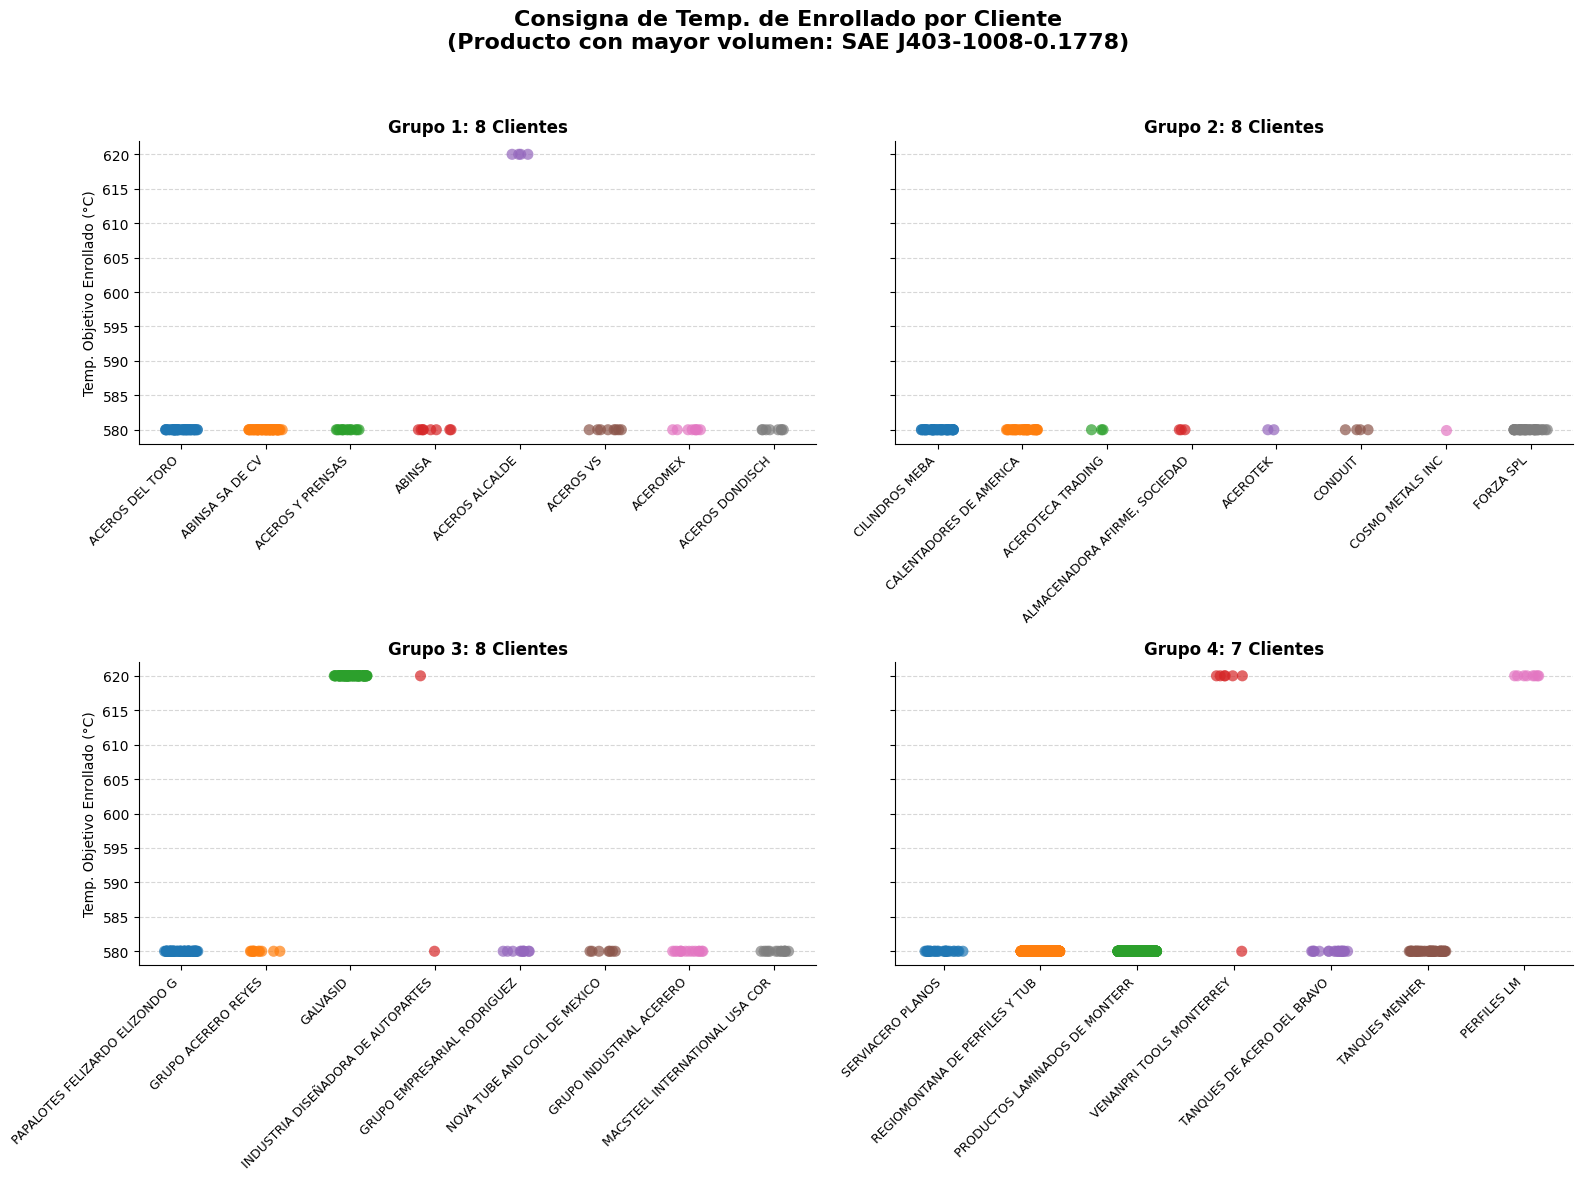

In [ ]:
# ORIGEN DE CONSIGNAS

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

# --- CREACIÓN DE RANGO_ESPESOR Y PRODUCTO_ID ---
col_min = [c for c in df.columns if 'espesor' in c.lower() and ('min' in c.lower() or 'mín' in c.lower())]
col_max = [c for c in df.columns if 'espesor' in c.lower() and ('max' in c.lower() or 'máx' in c.lower())]

if col_min and col_max:
    espesor_min_num = pd.to_numeric(df[col_min[0]], errors='coerce')
    espesor_max_num = pd.to_numeric(df[col_max[0]], errors='coerce')
    df['Rango_Espesor'] = (espesor_max_num - espesor_min_num).round(4).astype(str)
else:
    df['Rango_Espesor'] = "0.0"

partes = []
for col in ['Norma', 'Grado', 'Rango_Espesor']:
    if col in df.columns:
        partes.append(df[col].astype(str))

if partes:
    df['Producto_ID'] = partes[0].str.cat(partes[1:], sep='-')
else:
    df['Producto_ID'] = 'Producto_Generico'

col_prod = 'Producto_ID'
col_temp_obj = 'Temp Enrollado Obj' if 'Temp Enrollado Obj' in df.columns else 'Temp_Objetivo_Enrollado'
col_cliente = 'Cliente' if 'Cliente' in df.columns else df.select_dtypes(include='object').columns[0]

# --- ANÁLISIS GLOBAL DE PRODUCTOS (Skinpass vs No Skinpass) ---
total_productos = df[col_prod].nunique()

if 'Ruta Teórica' in df.columns:
    # Identificar qué productos tienen 'SKP_PSQ' en al menos uno de sus registros
    df['Tiene_SKP'] = df['Ruta Teórica'].astype(str).str.contains('SKP_PSQ', na=False, case=True)
    productos_con_skp_global = df[df['Tiene_SKP']][col_prod].nunique()
    productos_sin_skp_global = total_productos - productos_con_skp_global
else:
    productos_con_skp_global = 0
    productos_sin_skp_global = total_productos

# 1. Identificar celdas con múltiples consignas
celdas_mult_consigna = df.groupby(col_prod)[col_temp_obj].nunique()
celdas_varias = celdas_mult_consigna[celdas_mult_consigna > 1]

# --- ANÁLISIS DE MULTI-CONSIGNAS CON SKP_PSQ ---
df_varias = df[df[col_prod].isin(celdas_varias.index)]

if 'Ruta Teórica' in df_varias.columns:
    contiene_skp_varias = df_varias['Ruta Teórica'].astype(str).str.contains('SKP_PSQ', na=False, case=True)
    productos_con_skp = df_varias[contiene_skp_varias][col_prod].nunique()
else:
    productos_con_skp = 0

print("--- METRICAS GENERALES DE PRODUCTOS (SKINPASS) ---")
print(f"Total de productos únicos (general): {total_productos}")
if 'Ruta Teórica' in df.columns:
    print(f"Productos únicos destinados a Skinpass (contienen 'SKP_PSQ'): {productos_con_skp_global}")
    print(f"Productos únicos NO destinados a Skinpass: {productos_sin_skp_global}")

print(f"\n--- METRICAS DE MULTIPLES CONSIGNAS ---")
print(f"Número de celdas de producto con >1 consigna de temperatura: {len(celdas_varias)}")
if 'Ruta Teórica' in df.columns:
    print(f"De estas, celdas de producto con >1 consigna que contienen 'SKP_PSQ' en Ruta Teórica: {productos_con_skp}")

if len(celdas_varias) > 0:
    # Seleccionar el producto con mayor volumen para la gráfica
    top_producto = df[df[col_prod].isin(celdas_varias.index)][col_prod].value_counts().index[0]
    df_top = df[df[col_prod] == top_producto].copy()

    # Obtener lista única de clientes ordenada
    clientes_unicos = sorted(df_top[col_cliente].dropna().unique())
    num_clientes = len(clientes_unicos)

    # Dividir los clientes en 4 grupos de la manera más equitativa posible
    grupos_clientes = np.array_split(clientes_unicos, 4)

    # 2. Generación de Gráfica Ejecutiva dividida en 4 subplots (2x2)
    fig, axes = plt.subplots(2, 2, figsize=(16, 12), sharey=True)
    axes = axes.flatten()  # Aplanar para iterar fácilmente

    for i, grupo in enumerate(grupos_clientes):
        ax = axes[i]
        # Filtrar datos de este grupo de clientes
        df_grupo = df_top[df_top[col_cliente].isin(grupo)]

        # Crear gráfico para el subgrupo
        sns.stripplot(data=df_grupo, x=col_cliente, y=col_temp_obj, hue=col_cliente,
                      palette='tab10', jitter=0.2, size=8, alpha=0.7, ax=ax, legend=False)

        ax.set_title(f'Grupo {i+1}: {len(grupo)} Clientes', fontsize=12, weight='bold')
        ax.set_xlabel('')
        ax.set_ylabel('Temp. Objetivo Enrollado (°C)' if i % 2 == 0 else '')

        # Rotar etiquetas del eje X para mejorar lectura
        ax.set_xticklabels(ax.get_xticklabels(), rotation=45, ha='right', fontsize=9)
        ax.spines['top'].set_visible(False)
        ax.spines['right'].set_visible(False)
        ax.grid(axis='y', linestyle='--', alpha=0.5)

    plt.suptitle(f'Consigna de Temp. de Enrollado por Cliente\n(Producto con mayor volumen: {top_producto})',
                 fontsize=16, weight='bold', y=0.98)
    plt.tight_layout(rect=[0, 0, 1, 0.95])
    plt.show()
else:
    print("No se encontraron productos con múltiples consignas diferentes.")

### Descarga y Listado de Archivos desde Google Drive
En esta sección, instalaremos las herramientas necesarias, descargaremos la carpeta compartida de Google Drive y listaremos los archivos descargados.

In [ ]:
# Instalar/actualizar gdown para descargar carpetas completas desde Google Drive de forma sencilla
!pip install --upgrade gdown

  Attempting uninstall: gdown
    Found existing installation: gdown 5.2.2
    Uninstalling gdown-5.2.2:
      Successfully uninstalled gdown-5.2.2


In [ ]:
import os
import gdown

# URL de la carpeta compartida
folder_url = 'https://drive.google.com/drive/folders/1ZT31mcZ_fW-3NNC3NHJ-OjU2EmOJ2CXT?usp=sharing'

# Descargar todo el contenido de la carpeta de Drive de manera correcta
gdown.download_folder(url=folder_url, use_cookies=False)

Retrieving folder contents


Processing file 1xMVD5rfnVwbSP-QyOsJe9kWrFsiKtKPB MC4_PSQ Abril 1 a 15 2025.xlsx
Processing file 148bbJlRC1Uyu3VDrEiHN9l90NpEOJ2Ac MC4_PSQ Abril 16 a 30 2025.xlsx
Processing file 1_4fVKUHJBtZMtYW_jgJ_CyTC2ZqEwnCU MC4_PSQ Agosto 1 a 15 2025.xlsx
Processing file 10YHfG-UG1-XW34HbAuNOB-hOd0Zt2ICf MC4_PSQ Agosto 16 a 31 2025.xlsx
Processing file 14gaxV_PPXt9EDIsGJbMT-ylskA654EK7 MC4_PSQ Diciembre 1 a 15 2025.xlsx
Processing file 1Mdjs04yilHoJGN3ZS72Xt2oU8z1P047d MC4_PSQ Diciembre 16 a 31 2025.xlsx
Processing file 1ot8-f1ti0h5rbWlzL8sIO7pnAXbS97KE MC4_PSQ Enero 1 a 15 2025.xlsx
Processing file 1Vr-busbt-q1eWeBAvG_Gfl82Zk9zIzBN MC4_PSQ Enero 16 a 31 2025.xlsx
Processing file 1MG8eXy2wKhYz-cvEFF5xOuzMzM5ZRUsI MC4_PSQ Febrero 1 a 15 2025.xlsx
Processing file 1KnhKDqb7mGhvAMWKfu-dNs7CswrAzuvS MC4_PSQ Febrero 16 a 28 2025.xlsx
Processing file 1Iy1KmeZcS1ngZCx5IFm4qJcEhcm6NhML MC4_PSQ Julio 1 a 15 2025.xlsx
Processing file 1XnFt4cAxG7qq7yqaRj8inEqMmEwXAboX MC4_PSQ Julio 16 a 31 2025.xlsx
Processi

Retrieving folder contents completed
Building directory structure
Building directory structure completed
Failed to download /content/Desarrollo de aplicaciones avanzadas de ciencias computacionales/MC4_PSQ Abril 1 a 15 2025.xlsx: Failed to retrieve file url:

	Cannot retrieve the public link of the file. You may need to change
	the permission to 'Anyone with the link', or have had many accesses.
	Check FAQ in https://github.com/wkentaro/gdown?tab=readme-ov-file#faq.

You may still be able to access the file from the browser:

	https://drive.google.com/uc?id=1xMVD5rfnVwbSP-QyOsJe9kWrFsiKtKPB

but Gdown can't. Please check connections and permissions.
Failed to download /content/Desarrollo de aplicaciones avanzadas de ciencias computacionales/MC4_PSQ Abril 16 a 30 2025.xlsx: Failed to retrieve file url:

	Cannot retrieve the public link of the file. You may need to change
	the permission to 'Anyone with the link', or have had many accesses.
	Check FAQ in https://github.com/wkentaro/gdown

DownloadError: Failed to download the following files:
- /content/Desarrollo de aplicaciones avanzadas de ciencias computacionales/MC4_PSQ Abril 1 a 15 2025.xlsx
- /content/Desarrollo de aplicaciones avanzadas de ciencias computacionales/MC4_PSQ Abril 16 a 30 2025.xlsx
- /content/Desarrollo de aplicaciones avanzadas de ciencias computacionales/MC4_PSQ Agosto 1 a 15 2025.xlsx
- /content/Desarrollo de aplicaciones avanzadas de ciencias computacionales/MC4_PSQ Agosto 16 a 31 2025.xlsx
- /content/Desarrollo de aplicaciones avanzadas de ciencias computacionales/MC4_PSQ Diciembre 1 a 15 2025.xlsx
- /content/Desarrollo de aplicaciones avanzadas de ciencias computacionales/MC4_PSQ Diciembre 16 a 31 2025.xlsx
- /content/Desarrollo de aplicaciones avanzadas de ciencias computacionales/MC4_PSQ Enero 1 a 15 2025.xlsx
- /content/Desarrollo de aplicaciones avanzadas de ciencias computacionales/MC4_PSQ Enero 16 a 31 2025.xlsx
- /content/Desarrollo de aplicaciones avanzadas de ciencias computacionales

In [ ]:
import os
import gdown

# Crear la carpeta de destino si no existe
dest_dir = '/content/Desarrollo de aplicaciones avanzadas de ciencias computacionales'
os.makedirs(dest_dir, exist_ok=True)

# Diccionario con los IDs de Google Drive de los archivos que fallaron
files_to_rescue = {
    "MC4_PSQ Junio 1 a 15 2025.xlsx": "1cMbbrVYHEVo3do6zOpgjNH4GSYP9LTu8",
    "MC4_PSQ Septiembre 1 a 15 2025.xlsx": "1IgVWSRKKUC7XQPVbN2u_beTJiLVlYDxI",
    "MC4_PSQ Septiembre 16 a 30 2025.xlsx": "1ZE4h760SDeNSK3UK6gREqWImWCWnzXwb"
}

print("Intentando descargar los archivos faltantes de manera individual...")
for filename, file_id in files_to_rescue.items():
    output_path = os.path.join(dest_dir, filename)
    if not os.path.exists(output_path):
        url = f'https://drive.google.com/uc?id={file_id}'
        try:
            print(f"\nDescargando: {filename}...")
            gdown.download(url, output_path, quiet=False, use_cookies=False)
        except Exception as e:
            print(f"No se pudo descargar {filename} individualmente. Error: {e}")
            print("Si el error persiste, por favor verifica que el archivo individual tenga permisos de 'Cualquier persona con el enlace'.")
    else:
        print(f"{filename} ya existe en el directorio.")

Intentando descargar los archivos faltantes de manera individual...
MC4_PSQ Junio 1 a 15 2025.xlsx ya existe en el directorio.

Descargando: MC4_PSQ Septiembre 1 a 15 2025.xlsx...
No se pudo descargar MC4_PSQ Septiembre 1 a 15 2025.xlsx individualmente. Error: Failed to retrieve file url:

	Cannot retrieve the public link of the file. You may need to change
	the permission to 'Anyone with the link', or have had many accesses.
	Check FAQ in https://github.com/wkentaro/gdown?tab=readme-ov-file#faq.

You may still be able to access the file from the browser:

	https://drive.google.com/uc?id=1IgVWSRKKUC7XQPVbN2u_beTJiLVlYDxI

but Gdown can't. Please check connections and permissions.
Si el error persiste, por favor verifica que el archivo individual tenga permisos de 'Cualquier persona con el enlace'.

Descargando: MC4_PSQ Septiembre 16 a 30 2025.xlsx...
No se pudo descargar MC4_PSQ Septiembre 16 a 30 2025.xlsx individualmente. Error: Failed to retrieve file url:

	Cannot retrieve the publ

In [ ]:
import os

dest_dir = '/content/Desarrollo de aplicaciones avanzadas de ciencias computacionales'
os.makedirs(dest_dir, exist_ok=True)

# IDs de los archivos de Septiembre que faltan
files_to_download = {
    "MC4_PSQ Septiembre 1 a 15 2025.xlsx": "1IgVWSRKKUC7XQPVbN2u_beTJiLVlYDxI",
    "MC4_PSQ Septiembre 16 a 30 2025.xlsx": "1ZE4h760SDeNSK3UK6gREqWImWCWnzXwb"
}

print("Iniciando descarga alternativa para saltar el bloqueo de Google...")
for filename, file_id in files_to_download.items():
    output_path = os.path.join(dest_dir, filename)

    # Usamos wget con un user-agent y manejo de confirmación de archivos grandes de Google Drive
    confirm_code_cmd = f'wget --quiet --save-cookies /tmp/cookies.txt --keep-session-cookies --no-check-certificate "https://docs.google.com/uc?export=download&id={file_id}" -O- | grep -o \x27confirm=[^&]*\x27'
    confirm_code = os.popen(confirm_code_cmd).read().strip()

    if confirm_code:
        download_cmd = f'wget --load-cookies /tmp/cookies.txt "https://docs.google.com/uc?export=download&{confirm_code}&id={file_id}" -O "{output_path}"'
    else:
        download_cmd = f'wget --no-check-certificate "https://docs.google.com/uc?export=download&id={file_id}" -O "{output_path}"'

    print(f"\nDescargando {filename}...")
    status = os.system(download_cmd)

    if status == 0 and os.path.exists(output_path) and os.path.getsize(output_path) > 1000:
        print(f"¡Éxito! Descargado correctamente: {filename}")
    else:
        # Si falla wget, intentamos un curl simple simulando navegador
        print(f"Fallo con wget, intentando con curl para {filename}...")
        curl_cmd = f'curl -L "https://drive.google.com/uc?export=download&id={file_id}" -A "Mozilla/5.0 (Windows NT 10.0; Win64; x64)" -o "{output_path}"'
        os.system(curl_cmd)
        if os.path.exists(output_path) and os.path.getsize(output_path) > 1000:
            print(f"¡Éxito con curl! Descargado: {filename}")
        else:
            print(f"No se pudo obtener {filename}. Esto confirma que el archivo en Drive requiere que cambies sus permisos de acceso a 'Cualquier persona con el enlace'.")

# Limpiar cookies temporales
if os.path.exists("/tmp/cookies.txt"):
    os.remove("/tmp/cookies.txt")

Iniciando descarga alternativa para saltar el bloqueo de Google...

Descargando MC4_PSQ Septiembre 1 a 15 2025.xlsx...
¡Éxito! Descargado correctamente: MC4_PSQ Septiembre 1 a 15 2025.xlsx

Descargando MC4_PSQ Septiembre 16 a 30 2025.xlsx...
Fallo con wget, intentando con curl para MC4_PSQ Septiembre 16 a 30 2025.xlsx...
¡Éxito con curl! Descargado: MC4_PSQ Septiembre 16 a 30 2025.xlsx


In [ ]:
import os

target_dir = '/content/Desarrollo de aplicaciones avanzadas de ciencias computacionales'
if os.path.exists(target_dir):
    archivos = sorted(os.listdir(target_dir))
    print(f"Archivos descargados con éxito en '{target_dir}' ({len(archivos)} archivos):")
    for archivo in archivos:
        if not archivo.startswith('.'):
            print(f"- {archivo}")
else:
    print(f"La carpeta {target_dir} no existe.")

Archivos descargados con éxito en '/content/Desarrollo de aplicaciones avanzadas de ciencias computacionales' (24 archivos):
- MC4_PSQ Abril 1 a 15 2025.xlsx
- MC4_PSQ Abril 16 a 30 2025.xlsx
- MC4_PSQ Agosto 1 a 15 2025.xlsx
- MC4_PSQ Agosto 16 a 31 2025.xlsx
- MC4_PSQ Diciembre 1 a 15 2025.xlsx
- MC4_PSQ Diciembre 16 a 31 2025.xlsx
- MC4_PSQ Enero 1 a 15 2025.xlsx
- MC4_PSQ Enero 16 a 31 2025.xlsx
- MC4_PSQ Febrero 1 a 15 2025.xlsx
- MC4_PSQ Febrero 16 a 28 2025.xlsx
- MC4_PSQ Julio 1 a 15 2025.xlsx
- MC4_PSQ Julio 16 a 31 2025.xlsx
- MC4_PSQ Junio 1 a 15 2025.xlsx
- MC4_PSQ Junio 16 a 30 2025.xlsx
- MC4_PSQ Marzo 1 a 15 2025.xlsx
- MC4_PSQ Marzo 16 a 31 2025.xlsx
- MC4_PSQ Mayo 1 a 15 2025.xlsx
- MC4_PSQ Mayo 16 a 31 2025.xlsx
- MC4_PSQ Noviembre 1 a 15 2025.xlsx
- MC4_PSQ Noviembre 16 a 30 2025.xlsx
- MC4_PSQ Octubre 1 a 15 2025.xlsx
- MC4_PSQ Octubre 16 a 31 2025.xlsx
- MC4_PSQ Septiembre 1 a 15 2025.xlsx
- MC4_PSQ Septiembre 16 a 30 2025.xlsx
